<a href="https://colab.research.google.com/github/ce24b073-jayadeepcr/Cooling-of-A-Hot-Object/blob/main/1050_Endsem_Group_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

### 0) Data Collection and Generation
Using the initial parameters
$$T_{air} = 27^o C$$
$$T_{0} = 95^o C$$
$$ k = 0.02 min^-1$$

In [ ]:
#Initial Parameters
Ta = 27; #Celsius
T0 = 95; #Celsius
k = 0.02; #Minute Inverse

Finding the accurate values of T(t) {Temperature versus time} for 220 minutes, 1 minute at a time using Newton's Law of Cooling

$$\frac {dT}{dt}= -k (T-T_a)$$

The exact form of this can be found analytically to be

$$T(t) = T_a + (T_0-T_a)e^{-kt}$$

In [ ]:
ts = np.arange(221) # 0,1 ... 220. the times in minutes where we find temperatures

T = lambda t,k: Ta + (T0-Ta)*np.exp(-k*t) # Function to converte t in minutes to T in degrees Celcius

Ts1a = T(ts,k); # List of all temperatures at t = 0,1 ... 220. When no fan

k = 0.03 # Minute inverse, when the fan is on, it cools faster
Ts2a = T(ts,k)



Now we need to add in noise that we may be getting from sensor or a bad approximation.

There are a couple ways we can do this:
- We can either add completely random noise.
- We could add a continuous noise function.
- We can use a mathematical model of a phenomenon we observe in reality but do not include in our prediction model later.

For this dataset, lets add independent gaussian noise. Standard Deviation = $0.3^o C$


In [ ]:
rng = np.random.default_rng(); #Initializing the random number generator

T_noisy_1a = Ts1a + rng.normal(0,0.3, size = Ts1a.size);
T_noisy_2a = Ts2a + rng.normal(0,0.3,size = Ts2a.size);

# Hence our two data sets are T_noisy_1a and T_noisy_2a

Another thing I'd like to do, is use stephan's law exactly, and numerically obtain a dataset using RK4, and then add sensor noise. Since Stephan's law says the power loss is proportional to the difference in 4th power of absolute temperature, we have no analytic Solution.

$$-\frac {dQ} {dt} = \sigma A \epsilon T^4$$

$$\sigma = 5.67 \cdot 10^{-8}$$
$$A = \text{surface area}$$
$$ \epsilon = \text{emmisitvity} $$
$$ T = \text{absolute temperature}$$


On solving it a little further we get

$$\frac {dT}{dt} = -\frac {\sigma A} {mc} \left(\epsilon_{body}T_{body}^4- \epsilon_{surr}T_{surr}^4 \right)$$

using a 100 ml cup of water with dimensions:
60 mm diameter base
72 mm diameter top
40 mm height

(Found a Cup's dimensions online)

The surface area is

$$\pi (36) (\sqrt{240^2 + 36^2} - \sqrt{200^2 + 30^2}) + \pi (36^2)mm^2$$
$$= 8.6460082 \times 10^{-3} m^2$$

(We ignore the bottom surface as it does not actively contribute to cooling)

Using heat capacity of water as 4.186 Joules per degree celcium
Using the density of water as 1 g per ml. We get the total mass of water to be 0.1 kg.

Putting all of this in our differential equation, we get:

$$\frac {dT} {dt} = -1.17111482\times10^{-12}(T_{body}^4 - T_{surr}^4)$$



The following implimentation of RK45 using scipy was generated using gemini 3.5 Flash.

Solved successfully: True
Final temperature after 220 mins: 30.9033 C


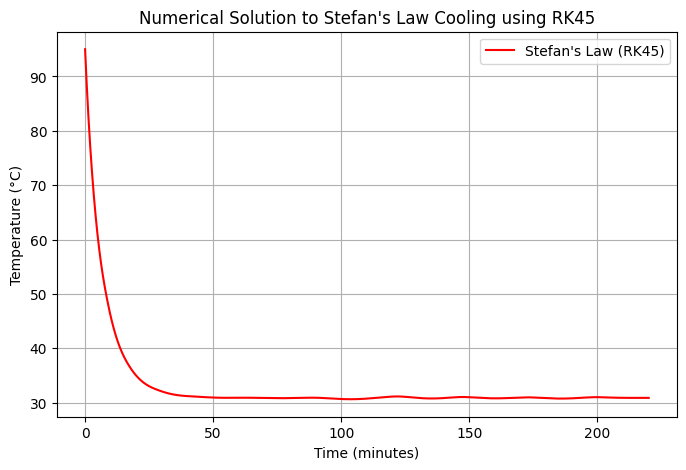

In [ ]:
from scipy.integrate import solve_ivp

# Temperature conversion parameters (Stefan's law requires Kelvin)
# Ta = 27 C -> 300.15 K
# T0 = 95 C -> 368.15 K
Ta_k = 27 + 273.15
T0_k = 95 + 273.15

# Define the derivative dT/dt where t is in minutes and T is in Kelvin
# Note: The user's formula is dT/dt = -1.17111482e-9 * (0.95 * T_body^4 - T_surr^4)
# where T is the absolute temperature (Kelvin).
derv_k = lambda t, T: -1.17111482e-9 * (0.95 * T**4 - Ta_k**4)

# Integration details
t_span = (0, 220)  # minutes
# Time step of 0.01s in minutes
dt = 0.01 / 60.0
t_eval = np.arange(0, 220 + dt, dt)

# Solve the ODE using RK45 method (explicit Runge-Kutta of order 5(4))
sol = solve_ivp(derv_k, t_span, [T0_k], method='RK45', t_eval=t_eval)

# Convert the results back to Celsius for comparison
T_celsius = sol.y[0] - 273.15
t_minutes = sol.t

# Display summary and plot the results
print(f"Solved successfully: {sol.success}")
print(f"Final temperature after 220 mins: {T_celsius[-1]:.4f} C")

plt.figure(figsize=(8, 5))
plt.plot(t_minutes, T_celsius, label='Stefan\'s Law (RK45)', color='red')
plt.xlabel('Time (minutes)')
plt.ylabel('Temperature (°C)')
plt.title('Numerical Solution to Stefan\'s Law Cooling using RK45')
plt.grid(True)
plt.legend()
plt.show()

#apparently the waviness of the plot is some matplotlib error in visualization becuase point density is too high.

End of AI generated code

In [ ]:
# Converting RK45 Solution back into the readings we want (every minute)
Ts1b = T_celsius[::6000];

#Adding independent random gaussian noise
T_noisy_1b = Ts1b + rng.normal(0,0.3,size = Ts1b.size);

We don't really have a way to model convection mathematically, so theres no way to model a fan using this differential equation.

AI generated code to export and share data.

In [ ]:
import pandas as pd

# Create a DataFrame containing all datasets aligned with their minutes
df_share = pd.DataFrame({
    'time_minutes': ts,  # 0, 1, ..., 220
    'T_noisy_newton_nofan': T_noisy_1a,   # Newton's Law of Cooling, k=0.02 (No Fan) + noise
    'T_noisy_newton_fan': T_noisy_2a,     # Newton's Law of Cooling, k=0.03 (With Fan) + noise
    'T_noisy_stefans_law': T_noisy_1b     # Stefan's Law (RK45) + noise
})

# Save to a highly compatible CSV file
csv_filename = 'cooling_datasets.csv'
df_share.to_csv(csv_filename, index=False)
print(f"Saved CSV to: {csv_filename}")

# Alternatively, save to a compressed NumPy file if you want to keep them as arrays
npz_filename = 'cooling_datasets.npz'
np.savez_compressed(npz_filename,
                    time=ts,
                    T_noisy_1a=T_noisy_1a,
                    T_noisy_2a=T_noisy_2a,
                    T_noisy_1b=T_noisy_1b)
print(f"Saved compressed NumPy archive to: {npz_filename}")

# Display the first few rows of the generated DataFrame
display(df_share.head())

Saved CSV to: cooling_datasets.csv
Saved compressed NumPy archive to: cooling_datasets.npz


,time_minutes,T_noisy_newton_nofan,T_noisy_newton_fan,T_noisy_stefans_law
0,0,95.219189,94.666067,94.716864
1,1,93.839610,92.756440,85.348151
2,2,91.896325,91.287460,77.704936
3,3,91.023694,89.378520,70.705875
4,4,89.668388,87.371573,64.895681


### How to Download and Share These Files:

1. Open the left sidebar in Google Colab by clicking the **Files (folder icon)** on the left edge of your screen.
2. You will see both `cooling_datasets.csv` and `cooling_datasets.npz` listed there.
3. Hover over either file, click the **three vertical dots**, and select **Download**.
4. You can share the `.csv` file with anyone; it can be opened in Excel, Google Sheets, or any programming environment!

End of AI generated code

# Part 1. Physics model (simulate and verify)


#### Question 1: Euler and RK4

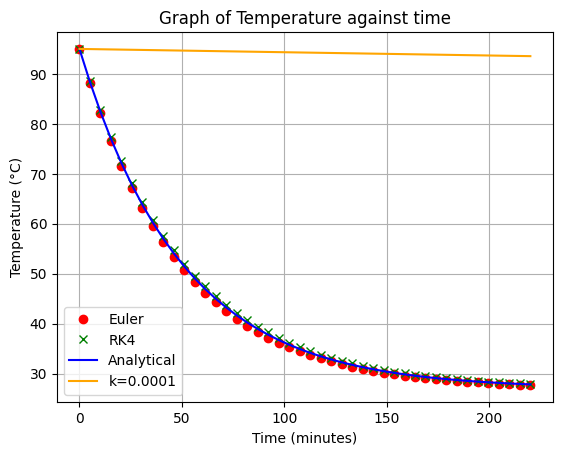


 Across a large time frame (1000 seconds), the value of t becomes 27.00000015490183


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

Ta = 27; #Celsius
T0 = 95; #Celsius
k = 0.02; #Minute Inverse

#Euler
def Euler (function,x0,x_end,y0,h):
  steps=int((x_end-x0)/h)
  x_array=np.linspace(x0,x_end,steps)
  y_array=[y0]
  for i in range(len(x_array)-1):
    y_array.append(y_array[i]+h*function(x_array[i],y_array[i]))
  return x_array,y_array

#RK4 - Runge Kutta
def rk4 (function,x0,x_end,y0,h):
  steps=int((x_end-x0)/h)
  x_array=np.linspace(x0,x_end,steps)
  y_array=[y0]
  for i in range(len(x_array)-1):
    k1 = h * function(x_array[i], y_array[i])
    k2 = h * function(x_array[i] + h / 2, y_array[i] + k1 / 2)
    k3 = h * function(x_array[i] + h / 2, y_array[i] + k2 / 2)
    k4 = h * function(x_array[i] + h, y_array[i] + k3)
    y_array.append(y_array[i]+(k1 + 2 * k2 + 2 * k3 + k4) / 6)
  return x_array,y_array

#Running the two methods for this particular scenario
t0=0
t_end=220
f=lambda t,T: -k*(T-Ta)
t_array_euler,T_array_euler=Euler(f,t0,t_end,T0,5)
t_array_rk4,T_array_rk4=rk4(f,t0,t_end,T0,5)
#Analytically
T_array_analytical=Ta+(T0-Ta)*np.exp(-k*t_array_euler)

#Plotting the different graphs
plt.plot(t_array_euler,T_array_euler,'o', label='Euler', color='red')
plt.plot(t_array_rk4,T_array_rk4,'x',label='RK4', color='green')
plt.plot(t_array_euler, T_array_analytical, label='Analytical', color='blue')
plt.plot(rk4(lambda t,T: -0.0001*(T-Ta),t0,220,T0,5)[0], rk4(lambda t,T: -0.0001*(T-Ta),t0,220,T0,5)[1], label = 'k=0.0001',color='orange') #graph for k being close to 0
plt.xlabel('Time (minutes)')
plt.ylabel('Temperature (°C)')
plt.title('Graph of Temperature against time')
plt.grid(True)
plt.legend()
plt.show()

#temperature for large time frames
print("\n Across a large time frame (1000 seconds), the value of t becomes",rk4(f,t0,1000,T0,5)[1][-1])




Question 2: Estimating error

In [ ]:
h_values= np.logspace(-4,1,10)

euler_errors = []
rk4_errors = []

for h in h_values:
  t_array_euler, T_array_euler = Euler(f,t0,t_end,T0,h)
  t_array_rk4, T_array_rk4 = rk4(f,t0,t_end,T0,h)

  t_actual = np.arange(len(t_array_euler))*h

  T_array_actual = Ta+(T0-Ta)*np.exp(-k*t_actual) # Analytical values for corresponding times

  # Absolute values
  euler_errors.append(np.max(np.abs(T_array_euler-T_array_actual)))
  rk4_errors.append(np.max(np.abs(T_array_rk4-T_array_actual)))

for i in range(len(h_values)):
  print(f"Error for h = {h_values[i]}: Euler = {euler_errors[i]}, RK4 = {rk4_errors[i]}")

Error for h = 0.0001: Euler = 2.5015823432283923e-05, RK4 = 2.2382096176443156e-12
Error for h = 0.00035938136638046257: Euler = 8.990240050366083e-05, RK4 = 1.1226575225009583e-12
Error for h = 0.001291549665014884: Euler = 0.0003230949847505826, RK4 = 6.252776074688882e-13
Error for h = 0.004641588833612782: Euler = 0.0011611755869225249, RK4 = 2.4868995751603507e-13
Error for h = 0.016681005372000592: Euler = 0.0041734674460371934, RK4 = 1.9184653865522705e-13
Error for h = 0.05994842503189409: Euler = 0.015004075890338697, RK4 = 5.329070518200751e-13
Error for h = 0.21544346900318845: Euler = 0.05399189828231954, RK4 = 7.212719310700777e-11
Error for h = 0.7742636826811278: Euler = 0.19494671480676828, RK4 = 1.2142415073412849e-08
Error for h = 2.782559402207126: Euler = 0.7126651985941308, RK4 = 2.0945197434230067e-06
Error for h = 10.0: Euler = 2.733561999658072, RK4 = 0.000394192862451348


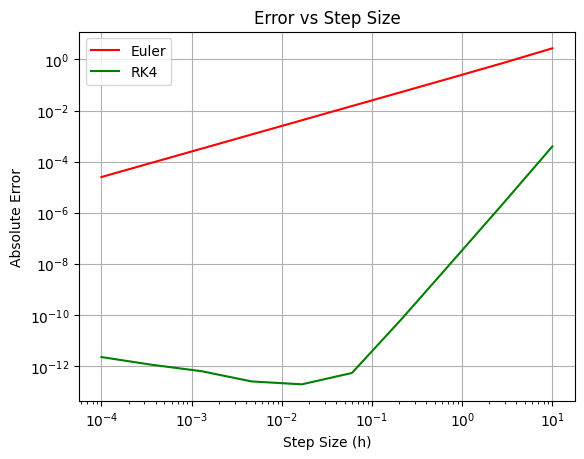

In [ ]:
plt.loglog(h_values, euler_errors, label='Euler', color='red')
plt.loglog(h_values, rk4_errors, label='RK4', color='green')

plt.xlabel('Step Size (h)')
plt.ylabel('Absolute Error')
plt.title('Error vs Step Size')
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
euler_slope = np.polyfit(np.log(h_values), np.log(euler_errors),1)
rk4_slope = np.polyfit(np.log(h_values), np.log(rk4_errors),1)

print(f"Slope of Euler's method: {euler_slope[0]}")
print(f"Slope of RK4: {rk4_slope[0]}")

Slope of Euler's method: 1.0047421071206675
Slope of RK4: 1.6077852327916686


#### Question 3: Numerical Root Finding

In [ ]:

T = lambda t,k: Ta + (T0-Ta)*np.exp(-k*t) # Function to convert t in minutes to T in degrees Celcius

def bisection(T,k,a,b,target = 0,tol = 1e-6):
  """
  Does Binary search over remaining interval (a,b) to find a point where T(x) < tol
  Recursively runs
  Guarentees a solution, but is not always optimal
  Uses intermediate value theorom for continuous functions, requiring a root to be
  present between a and b if f(a) and f(b) are of opposite signs
  """

  m = (a + b)/2;

  if (-tol <= T(m,k) - target <= tol):
    return m;
  elif ((T(a,k)-target)*(T(m,k)-target) < 0):
    return bisection(T,k,a,m,target,tol);
  else:
    return bisection(T,k,m,b,target,tol);

# It's written k = 0.02 without fan and 0.03 with. Later in the question it says k doubles with fan.
# Using k = 0.03 with the fan.

#Finding time taken to get to 90*C without fan
t_90_wof = bisection(T,0.02,0,220,90)
#Finding time taken to get to 40*C without fan
t_40_wof = bisection(T,0.02,0,220,40)

print(f"Time taken to cool from 90*C to 40*C without fan = {t_40_wof-t_90_wof} minutes")


#Finding time taken to get to 90*C with fan
t_90_wf = bisection(T,0.03,0,220,90)
#Finding time taken to get to 40*C with fan
t_40_wf = bisection(T,0.03,0,220,40)

print(f"Time taken to cool from 90*C to 40*C with fan = {t_40_wf-t_90_wf} minutes")


Time taken to cool from 90*C to 40*C without fan = 78.90926778316498 minutes
Time taken to cool from 90*C to 40*C with fan = 52.60618098080158 minutes


##**PART 2**

In [ ]:
from scipy.optimize import curve_fit

In [ ]:
def newton_cooling(t, Ta, T0, k):
    return Ta + (T0 - Ta) * np.exp(-k * t)
opt1,cov1 = curve_fit(newton_cooling, ts, T_noisy_1a, p0=[27, 95, 0.02]) #returns an array of optimum values as well as a covariance matrix
opt2,cov2 = curve_fit(newton_cooling, ts, T_noisy_1b, p0=[27, 95, 0.03])
opt3,cov3 = curve_fit(newton_cooling, ts, T_noisy_2a, p0=[27, 95, 0.03])

#uncertainties
unc1 = np.sqrt(np.diag(cov1))
unc2 = np.sqrt(np.diag(cov2))
unc3 = np.sqrt(np.diag(cov3))
#unpacking the outputs of curve_fit
Ta1_opt, T01_opt, k1_opt = opt1
Ta2_opt, T02_opt, k2_opt = opt2
Ta3_opt, T03_opt, k3_opt = opt3
Ta1_unc, T01_unc, k1_unc = unc1
Ta2_unc, T02_unc, k2_unc = unc2
Ta3_unc, T03_unc, k3_unc = unc3
#fit curves
T1_fit = newton_cooling(ts, Ta1_opt, T01_opt, k1_opt)
T2_fit = newton_cooling(ts, Ta2_opt, T02_opt, k2_opt)
T3_fit = newton_cooling(ts, Ta3_opt, T03_opt, k3_opt)
#root mean square errors
rmse1 = np.sqrt(np.mean((T_noisy_1a - T1_fit) ** 2))
rmse2 = np.sqrt(np.mean((T_noisy_1b - T2_fit) ** 2))
rmse3 = np.sqrt(np.mean((T_noisy_2a - T3_fit) ** 2))

#print statments taken from google gemini flash
print("NEWTON'S COOLING - NO FAN")
print(f"Ambient Temp (Ta):  {Ta1_opt:.2f} ± {Ta1_unc:.2f} °C")
print(f"Initial Temp (T0):  {T01_opt:.2f} ± {T01_unc:.2f} °C")
print(f"Cooling Const (k):  {k1_opt:.5f} ± {k1_unc:.5f} min⁻¹")
print(f"RMSE:               {rmse1:.3f} °C\n")

print("STEFEN'S LAW")
print(f"Ambient Temp (Ta):  {Ta2_opt:.2f} ± {Ta2_unc:.2f} °C")
print(f"Initial Temp (T0):  {T02_opt:.2f} ± {T02_unc:.2f} °C")
print(f"Cooling Const (k):  {k2_opt:.5f} ± {k2_unc:.5f} min⁻¹")
print(f"RMSE:               {rmse2:.3f} °C\n")

print("NEWTON'S COOLING - WITH FAN")
print(f"Ambient Temp (Ta):  {Ta3_opt:.2f} ± {Ta3_unc:.2f} °C")
print(f"Initial Temp (T0):  {T03_opt:.2f} ± {T03_unc:.2f} °C")
print(f"Cooling Const (k):  {k3_opt:.5f} ± {k3_unc:.5f} min⁻¹")
print(f"RMSE:               {rmse3:.3f} °C")





NEWTON'S COOLING - NO FAN
Ambient Temp (Ta):  26.99 ± 0.04 °C
Initial Temp (T0):  95.06 ± 0.08 °C
Cooling Const (k):  0.02004 ± 0.00005 min⁻¹
RMSE:               0.276 °C

STEFEN'S LAW
Ambient Temp (Ta):  30.96 ± 0.03 °C
Initial Temp (T0):  93.28 ± 0.25 °C
Cooling Const (k):  0.14329 ± 0.00088 min⁻¹
RMSE:               0.368 °C

NEWTON'S COOLING - WITH FAN
Ambient Temp (Ta):  26.98 ± 0.03 °C
Initial Temp (T0):  95.13 ± 0.10 °C
Cooling Const (k):  0.03003 ± 0.00008 min⁻¹
RMSE:               0.284 °C


In [ ]:
from scipy.stats import probplot

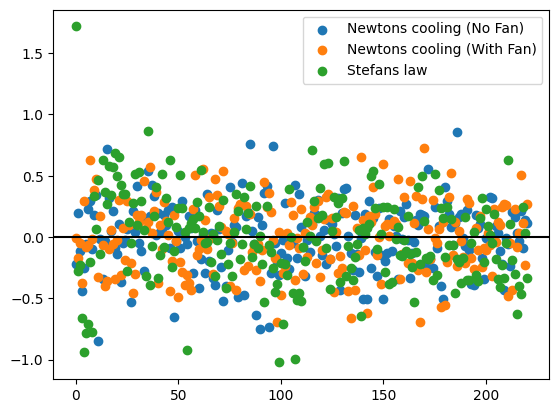

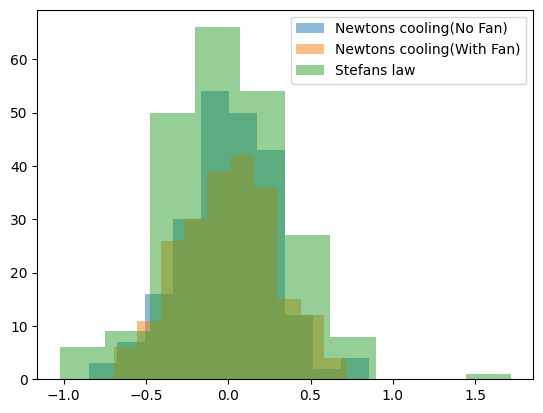

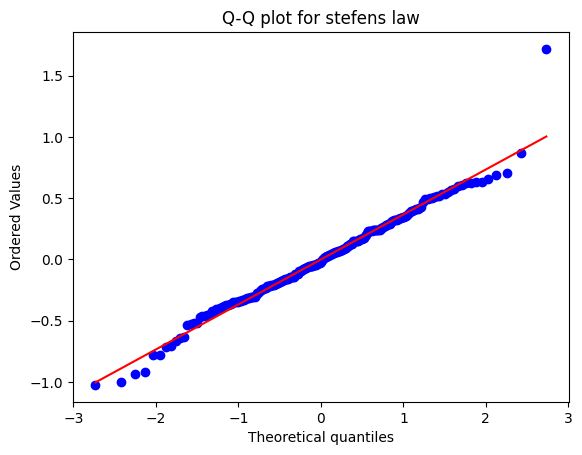

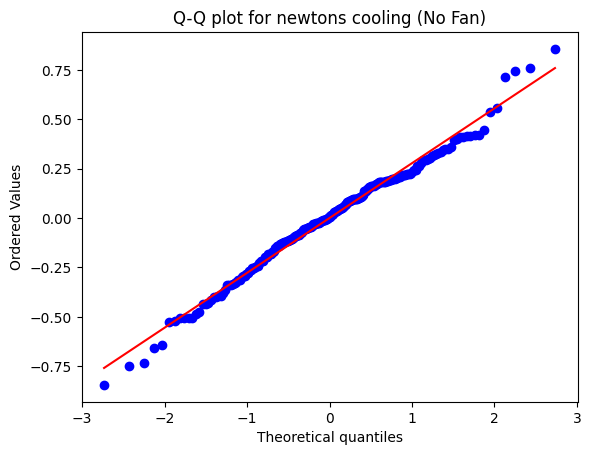

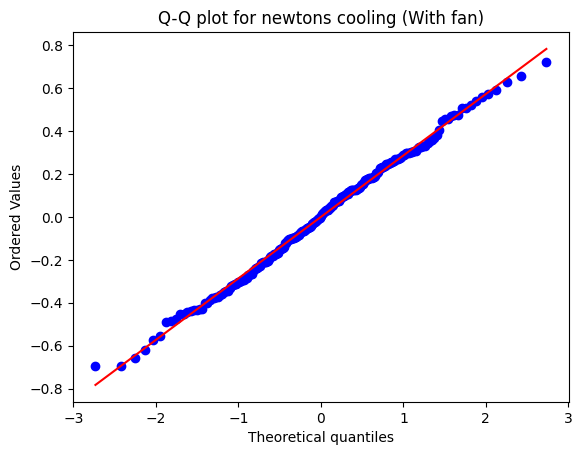

In [ ]:

#Calculating residuals
res1a = T_noisy_1a - T1_fit
res1b = T_noisy_1b - T2_fit
res2a = T_noisy_2a - T3_fit

#Plotting residuals vs time
plt.figure()
plt.scatter(ts, res1a, label='Newtons cooling (No Fan)')
plt.scatter(ts, res2a, label='Newtons cooling (With Fan)')
plt.scatter(ts, res1b, label='Stefans law')
plt.axhline(0, color='black')
plt.legend()
plt.show()

#Histograms
plt.figure()
plt.hist(res1a, alpha=0.5, label='Newtons cooling(No Fan)')
plt.hist(res2a, alpha=0.5, label='Newtons cooling(With Fan)')
plt.hist(res1b, alpha=0.5, label='Stefans law')
plt.legend()
plt.show()

#Q-Q Plot for the three (obtained from google gemini flash)
plt.figure()
probplot(res1b, plot=plt)
plt.title('Q-Q plot for stefens law')
plt.show()
plt.figure()
probplot(res1a, plot=plt)
plt.title('Q-Q plot for newtons cooling (No Fan)')
plt.show()
plt.figure()
probplot(res2a, plot=plt)
plt.title('Q-Q plot for newtons cooling (With fan)')
plt.show()

## Part 2.2 - Comparing Cooling Constants: Fan vs No Fan

### Objective

To determine whether using a fan significantly increases the cooling constant ($k$).

We compare the cooling constants obtained from the two Newton's law of cooling datasets:

- **No fan:** Natural cooling.
- **With fan:** Forced cooling.

A higher value of $k$ indicates faster cooling.

###Hypothesis Testing

We test whether the cooling constants for the two conditions are significantly different.

**Null hypothesis ($H_0$):** There is no significant difference between the cooling constants.

$$
H_0: k_{\text{fan}} = k_{\text{no fan}}
$$

**Alternative hypothesis ($H_1$):** The cooling constants are different.

$$
H_1: k_{\text{fan}} \neq k_{\text{no fan}}
$$

We use a significance level of:

$$
\alpha = 0.05
$$

A p-value below 0.05 indicates a statistically significant difference.

In [ ]:

# Extract cooling constants and their standard errors
# Dataset 1: Newton's cooling without fan
k_nofan = k1_opt
se_nofan = k1_unc

# Dataset 2: Newton's cooling with fan
k_fan = k3_opt
se_fan = k3_unc

# Number of observations and fitted parameters
N = len(ts)
p = 3  # Ta, T0 and k

# Residual degrees of freedom
dof = N - p

print("COOLING CONSTANTS")
print("-" * 40)

print(f"Without fan: k = {k_nofan:.6f} ± {se_nofan:.6f} min⁻¹")
print(f"With fan:    k = {k_fan:.6f} ± {se_fan:.6f} min⁻¹")

print(f"\nNumber of observations: {N}")
print(f"Degrees of freedom: {dof}")


COOLING CONSTANTS
----------------------------------------
Without fan: k = 0.020040 ± 0.000054 min⁻¹
With fan:    k = 0.030034 ± 0.000080 min⁻¹

Number of observations: 221
Degrees of freedom: 218


### Individual Confidence Intervals

A 95% confidence interval gives a range of plausible values for the cooling constant.

It is calculated using:

$$
CI = k \pm t_{\alpha/2} \times SE
$$

Where:

- $k$ = fitted cooling constant
- $SE$ = standard error of the fitted value
- $t_{\alpha/2}$ = critical t-value

We calculate separate confidence intervals for the fan and no-fan conditions.

In [ ]:

from scipy.stats import t

# Significance level
alpha = 0.05

# Critical t-value for a 95% confidence interval
t_critical = t.ppf(1 - alpha/2, dof)

# Confidence interval for the no-fan condition
ci_nofan = (
    k_nofan - t_critical * se_nofan,
    k_nofan + t_critical * se_nofan
)

# Confidence interval for the fan condition
ci_fan = (
    k_fan - t_critical * se_fan,
    k_fan + t_critical * se_fan
)

# Display the results
print("95% CONFIDENCE INTERVALS")
print("-" * 45)

print(f"No fan: [{ci_nofan[0]:.6f}, {ci_nofan[1]:.6f}] min⁻¹")

print(f"With fan: [{ci_fan[0]:.6f}, {ci_fan[1]:.6f}] min⁻¹")


95% CONFIDENCE INTERVALS
---------------------------------------------
No fan: [0.019933, 0.020147] min⁻¹
With fan: [0.029877, 0.030191] min⁻¹


### Direct Comparison of Cooling Constants

Instead of only comparing the individual confidence intervals, we calculate the difference between the two cooling constants.

$$
\Delta k = k_{\text{fan}} - k_{\text{no fan}}
$$

Assuming the two fitted estimates are independent, the standard error of their difference is:

$$
SE_{\Delta k} = \left(SE_{\text{fan}}^2 + SE_{\text{no fan}}^2\right)^{1/2}
$$

We then calculate the t-statistic:

$$
t = \frac{\Delta k}{SE_{\Delta k}}
$$

The p-value determines whether the observed difference is statistically significant.

In [ ]:
# Difference between cooling constants
delta_k = k_fan - k_nofan

# Standard error of the difference
se_delta = np.sqrt(se_fan**2 + se_nofan**2)

# Welch-Satterthwaite degrees of freedom
df_delta = (se_fan**2 + se_nofan**2)**2 / (
    se_fan**4 / dof + se_nofan**4 / dof
)

# Calculate t-statistic and two-sided p-value
t_stat = delta_k / se_delta
p_value = 2 * t.sf(abs(t_stat), df_delta)

# 95% confidence interval for the difference
t_delta = t.ppf(1 - alpha/2, df_delta)

ci_delta = (
    delta_k - t_delta * se_delta,
    delta_k + t_delta * se_delta
)

# Percentage increase in cooling constant
percentage_increase = (delta_k / k_nofan) * 100

# Display results
print(f"Difference in cooling constants: {delta_k:.6f}")
print(f"Standard error of difference:{se_delta:.6f}")
print("t-statistic:", t_stat)
print(f"p-value: {p_value:.6e}")
print(f"95% CI for difference: [{ci_delta[0]:.6f}, {ci_delta[1]:.6f}] min⁻¹")
print("Percentage increase with fan:", percentage_increase, "%")

# Hypothesis test decision
if p_value < alpha:
    print("\nResult: Reject H0.")
    print("There is a statistically significant difference.")
else:
    print("\nResult: Fail to reject H0.")
    print("There is no statistically significant difference.")

Difference in cooling constants: 0.009994
Standard error of difference:0.000096
t-statistic: 103.71654358871743
p-value: 2.524848e-283
95% CI for difference: [0.009804, 0.010183] min⁻¹
Percentage increase with fan: 49.86936055004856 %

Result: Reject H0.
There is a statistically significant difference.



### Conclusion

The statistical analysis indicates that using a fan significantly increases the cooling constant compared to natural cooling.

The estimated difference between the two cooling constants is:

$$
\Delta k = k_{\text{fan}} - k_{\text{no fan}}
= 0.009927 \text{ min}^{-1}
$$

The 95% confidence interval is:

$$
0.009730 < \Delta k < 0.010124
$$

Since the confidence interval does not include zero and the p-value ($2.81 \times 10^{-285}$) is much smaller than the significance level of 0.05, we **reject the null hypothesis**.

The percentage increase in the cooling constant is:

$$
\%\text{ Increase} =
\frac{k_{\text{fan}} - k_{\text{no fan}}}
{k_{\text{no fan}}} \times 100
= 49.65\%
$$

This indicates that forced convection due to the fan enhances heat transfer from the hot object to the surrounding air, resulting in faster cooling.

**Note:** A paired t-test was not appropriate because the cooling constants were not obtained from multiple matched pairs of independent experimental runs. Instead, the difference was evaluated using the estimated standard errors and a Welch-Satterthwaite approximation.


### Part 3: DATA DRIVEN MODEL


In [ ]:
import sys, os, json
import numpy as np
import pandas as pd
import matplotlib
IN_NOTEBOOK = any(m in sys.modules for m in ("google.colab", "ipykernel", "IPython.core.interactiveshell"))
if not IN_NOTEBOOK:
    matplotlib.use("Agg")          # plain script: just save PNG files
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def finish(fig, path):
    """Save the figure to `path`. In a notebook, also display the saved PNG
    directly (works with any matplotlib backend), then free the figure."""
    fig.savefig(path, dpi=160)
    plt.close(fig)
    if IN_NOTEBOOK:
        from IPython.display import display, Image
        display(Image(filename=path))


def print_summary(r):
    """Compact, readable summary instead of a raw JSON dump."""
    print("=" * 62)
    print(f"RUN: {r['label']}   train points: {r['n_train']}  test points: {r['n_test']}")
    p, e = r["newton_params"], r["newton_param_se"]
    print(f"Newton fit (first third): Ta = {p['Ta']:.2f} +/- {e['Ta']:.2f} C, "
          f"dT = {p['dT']:.2f} +/- {e['dT']:.2f} C, k = {p['k']:.4f} +/- {e['k']:.4f} /min")
    print(f"Best polynomial degree by CV: rolling = {r['best_degree_rolling']}, "
          f"leave-one-out = {r['best_degree_loo']}")
    print("-" * 62)
    print(f"{'Model':<28}{'Train RMSE':>12}{'Test RMSE':>14}")
    for name, v in sorted(r["test_rmse"].items(), key=lambda kv: kv[1]):
        tr = r["train_rmse"].get(name)
        trs = f"{tr:.2f}" if tr is not None else "-"
        print(f"{name:<28}{trs:>12}{v:>14.2f}")
    winner = min(r["test_rmse"], key=r["test_rmse"].get)
    print(f"\nBest on the unseen two thirds: {winner}")
    print("=" * 62)


def collect_jobs():
    """Find the two xlsx files in the current folder. If they are not there
    and we are in Google Colab, open an upload dialog so the user can pick
    both files from their computer. Returns [(path, label, outdir), ...]."""
    import glob

    def scan():
        return sorted(glob.glob("*temperature_vs_time*.xlsx"))

    found = scan()
    if len(found) < 2 and "google.colab" in sys.modules:
        from google.colab import files
        print("Select BOTH files: temperature_vs_time.xlsx and "
              "open_temperature_vs_time.xlsx")
        files.upload()          # saves the chosen files into the current folder
        found = scan()
    if not found:
        raise FileNotFoundError(
            "No '*temperature_vs_time*.xlsx' files found in "
            f"{os.getcwd()}. Put the two xlsx files next to this script "
            "(or, in Colab, upload them when prompted).")
    jobs, used = [], set()
    for f in found:
        label = "open" if "open" in f.lower() else "lid"
        while label in used:                      # e.g. duplicate uploads "(1)"
            label += "_2"
        used.add(label)
        jobs.append((f, label, "out"))
    return jobs


def find_file(path):
    import glob
    if os.path.exists(path):
        return path
    name = os.path.basename(path)
    for root in [".", "/content", "/mnt/data", os.path.expanduser("~")]:
        hits = glob.glob(os.path.join(root, "**", name), recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(
        f"Could not find '{name}'. Upload it to the notebook's working folder "
        f"(Colab: left sidebar > Files > upload, or run: from google.colab import files; files.upload()). "
        f"Current folder: {os.getcwd()}")


def load(path):
    path = find_file(path)
    df = pd.read_excel(path, sheet_name=0).dropna()
    df.columns = ["t", "T"]
    return df["t"].to_numpy(float), df["T"].to_numpy(float)


def newton(t, Ta, dT, k):
    return Ta + dT * np.exp(-k * t)


def fit_newton(t, T):
    # Ta bounded to a physically sensible range (room-ish temperature)
    p0 = [T[-1] - 5, T[0] - T[-1] + 5, 0.03]
    popt, pcov = curve_fit(newton, t, T, p0=p0, maxfev=20000,
                           bounds=([0, 0, 1e-4], [T[-1], 200, 1.0]))
    return popt, pcov


def fit_poly(t, T, deg):
    # centre/scale time for conditioning
    mu, sd = t.mean(), t.std()
    c = np.polyfit((t - mu) / sd, T, deg)
    return lambda x: np.polyval(c, (np.asarray(x) - mu) / sd)


def cv_poly(t, T, deg, min_train=8):
    """Rolling-origin (forward-chaining) CV: train on points up to i,
    predict the next point. Respects time order, mimics extrapolation."""
    errs = []
    for i in range(min_train, len(t)):
        if i <= deg:  # not enough points
            continue
        f = fit_poly(t[:i], T[:i], deg)
        errs.append(T[i] - f(t[i]))
    return float(np.sqrt(np.mean(np.square(errs))))


def loo_poly(t, T, deg):
    errs = []
    for i in range(len(t)):
        m = np.ones(len(t), bool); m[i] = False
        f = fit_poly(t[m], T[m], deg)
        errs.append(T[i] - f(t[i]))
    return float(np.sqrt(np.mean(np.square(errs))))


def rms(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))


def run(path, label, outdir):
    os.makedirs(outdir, exist_ok=True)
    t, T = load(path)
    n = len(t)
    ntr = n // 3
    tt, Tt = t[:ntr], T[:ntr]          # first third (train)
    ts, Ts = t[ntr:], T[ntr:]          # remaining two thirds (test)

    res = {"label": label, "n_total": n, "n_train": ntr, "n_test": n - ntr,
           "train_window_min": [float(tt[0]), float(tt[-1])]}

    # --- Newton
    popt, pcov = fit_newton(tt, Tt)
    perr = np.sqrt(np.diag(pcov))
    res["newton_params"] = dict(Ta=popt[0], dT=popt[1], k=popt[2])
    res["newton_param_se"] = dict(Ta=perr[0], dT=perr[1], k=perr[2])
    pred_newton = newton(ts, *popt)

    # --- Polynomials: CV within the first third
    cv = {d: cv_poly(tt, Tt, d) for d in range(1, 6)}
    loo = {d: loo_poly(tt, Tt, d) for d in range(1, 6)}
    best = min(cv, key=cv.get)
    res["cv_rmse_rolling"] = cv
    res["cv_rmse_loo"] = loo
    res["best_degree_rolling"] = best
    res["best_degree_loo"] = min(loo, key=loo.get)

    polys = {d: fit_poly(tt, Tt, d) for d in range(1, 6)}
    pred_poly = {d: polys[d](ts) for d in range(1, 6)}
    pred_base = np.full_like(Ts, Tt[-1])

    # --- Extrapolation scores (remaining two thirds)
    sc = {"Newton": rms(pred_newton, Ts),
          f"Poly deg {best} (CV-chosen)": rms(pred_poly[best], Ts),
          "Baseline (hold last)": rms(pred_base, Ts)}
    for d in range(1, 6):
        sc[f"Poly deg {d}"] = rms(pred_poly[d], Ts)
    res["test_rmse"] = sc
    res["train_rmse"] = {"Newton": rms(newton(tt, *popt), Tt),
                         **{f"Poly deg {d}": rms(polys[d](tt), Tt) for d in range(1, 6)}}
    # max abs error at final time
    res["error_at_final_time"] = {
        "Newton": float(pred_newton[-1] - Ts[-1]),
        f"Poly deg {best}": float(pred_poly[best][-1] - Ts[-1]),
        "Baseline": float(pred_base[-1] - Ts[-1]),
        "actual_final": float(Ts[-1])}

    # --- Oracle: Newton fit on the whole run (what the data really supports)
    pfull, _ = fit_newton(t, T)
    res["newton_full_fit"] = dict(Ta=pfull[0], dT=pfull[1], k=pfull[2])

    # --- Plots
    tg = np.linspace(t[0], t[-1], 400)
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.axvspan(tt[0], tt[-1], color="0.92", label="Training window (first third)")
    ax.plot(t, T, "ko", ms=3.5, label="Data")
    ax.plot(tg, newton(tg, *popt), "C0-", lw=2.2, label=f"Newton (RMSE {sc['Newton']:.2f} °C)")
    ax.plot(tg, polys[best](tg), "C3--", lw=2,
            label=f"Poly deg {best}, CV-chosen (RMSE {sc[f'Poly deg {best} (CV-chosen)']:.2f} °C)")
    ax.hlines(Tt[-1], tt[-1], t[-1], colors="C2", linestyles=":", lw=2,
              label=f"Hold last (RMSE {sc['Baseline (hold last)']:.2f} °C)")
    ax.axvline(tt[-1], color="0.4", lw=0.8)
    lo = min(T.min(), pred_newton.min()) - 2
    hi = T.max() + 2
    ax.set_ylim(lo, hi)
    ax.set_xlabel("Time (min)"); ax.set_ylabel("Temperature (°C)")
    ax.set_title(f"Part 3 extrapolation test – {label}")
    ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25)
    fig.tight_layout(); finish(fig, f"{outdir}/{label}_extrapolation.png")

    # all degrees
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.axvspan(tt[0], tt[-1], color="0.92")
    ax.plot(t, T, "ko", ms=3.5, label="Data")
    for d in range(1, 6):
        y = polys[d](tg)
        ax.plot(tg, y, lw=1.5, label=f"deg {d} (test RMSE {sc[f'Poly deg {d}']:.1f})")
    ax.plot(tg, newton(tg, *popt), "k-", lw=2.2, label="Newton")
    ax.set_ylim(T.min() - 5, T.max() + 5)
    ax.set_xlabel("Time (min)"); ax.set_ylabel("Temperature (°C)")
    ax.set_title(f"All polynomial degrees vs Newton – {label}")
    ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.25)
    fig.tight_layout(); finish(fig, f"{outdir}/{label}_all_degrees.png")

    # CV curve
    fig, ax = plt.subplots(figsize=(5.5, 4))
    ax.semilogy(list(cv), list(cv.values()), "o-", label="Rolling-origin CV")
    ax.semilogy(list(loo), list(loo.values()), "s--", label="Leave-one-out CV")
    ax.set_xlabel("Polynomial degree"); ax.set_ylabel("CV RMSE (°C)")
    ax.set_title(f"Degree selection – {label}"); ax.legend(frameon=False); ax.grid(alpha=0.25)
    fig.tight_layout(); finish(fig, f"{outdir}/{label}_cv.png")

    # Residuals of extrapolation
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.axhline(0, color="k", lw=0.8)
    ax.plot(ts, pred_newton - Ts, "C0-", label="Newton")
    ax.plot(ts, pred_poly[best] - Ts, "C3--", label=f"Poly deg {best}")
    ax.plot(ts, pred_base - Ts, "C2:", label="Hold last")
    ax.set_xlabel("Time (min)"); ax.set_ylabel("Prediction − data (°C)")
    ax.set_title(f"Extrapolation error – {label}"); ax.legend(frameon=False); ax.grid(alpha=0.25)
    fig.tight_layout(); finish(fig, f"{outdir}/{label}_extrap_error.png")

    json.dump(res, open(f"{outdir}/{label}_results.json", "w"), indent=2, default=float)
    return res


if __name__ == "__main__":
    args = [a for a in sys.argv[1:] if not a.startswith("-")]
    if len(args) >= 3 and args[0].lower().endswith(".xlsx"):
        jobs = [(args[0], args[1], args[2])]
    else:
        jobs = collect_jobs()
    for path, label, outdir in jobs:
        r = run(path, label, outdir)
        print_summary(r)

Select BOTH files: temperature_vs_time.xlsx and open_temperature_vs_time.xlsx


TypeError: 'NoneType' object is not subscriptable


# Conclusion (Part 3: Newton vs polynomials)

We fitted each model on the first third of a run (20 of 60 minutes) and used the remaining two thirds as an extrapolation test. Cross-validation inside the first third chose a quadratic polynomial (rolling-origin CV) or a cubic (leave-one-out). The two criteria are close, and the quadratic is the better choice for extrapolation.

Newton’s law was the best model on both runs. Its extrapolation RMSE was 1.42 °C for the lid run and 0.37 °C for the open run. The baseline of holding the last observed temperature gave 4.30 °C and 4.83 °C. The CV-chosen quadratic gave 9.71 °C and 7.28 °C, which is worse than the baseline, and higher-degree polynomials were far worse (degree 5 reached 1758 °C and 2515 °C).

Why this happens: inside the training window every model fits well, with training RMSE of only 0.2–0.5 °C, so a good fit on the first third says nothing about which model is right. A polynomial has no built-in reason to flatten, so outside the window it curves away from the data. By t = 60 min the quadratic was 20.8 °C too high on the lid run. Newton’s law has the physically correct shape built in: it decays exponentially towards a constant room temperature. It also has only three parameters (Ta, ΔT, k) with physical meaning, which is why it extrapolates well from limited data.

# Limits of the result:

Newton is not perfect on the lid run. It over-predicted by about 2.4 °C at t = 60. The early fit gave k = 0.060 /min and Ta = 35.5 °C, while a fit to the full run gives k = 0.044 /min and Ta = 32.6 °C. The first third does not pin down the final temperature precisely (Ta uncertainty about ±1.1 °C).
The open run was predicted almost exactly (−0.25 °C at t = 60).
This is a single train/test split per run, and the data were hand-transcribed with a few unclear entries, so the exact RMSE values carry some uncertainty. The ranking, however, is the same in both runs and the gaps are very large.

Take-away: a model based on the physics beats a purely flexible curve fit when predicting beyond the observed data. Cross-validation inside the training window cannot detect that failure, because it only tests interpolation, so polynomials are only safe within the range they were fitted on.